# Corporate AI accountability research project for VS Code
Team LogicFlow — Bhavishya Gottipati and Parvathy Venugopal

This expands the supplied code.ipynb: local CSV/Excel loading, cleaning, candidate screening, report analysis, human review and evaluation remain the foundation. It adds stage analysis, principle comparisons, all 16 planned RQ outputs and export packaging. The original four screening dictionaries are preserved as a baseline; the expanded framework distinguishes evidence artefacts from assurance activities.

The executed copy contains real descriptive analysis of the included OECD CSV. Textual co-occurrence is a candidate measure. Human-confirmed chains and precision/recall remain pending until genuine review labels are supplied. No missing human ratings are simulated. RQ3 uses countries and periods because sectors/document types are absent.

Open this folder in VS Code, select your Python environment, and Run All. All paths resolve inside the extracted project. The .py implementation contains matching `# %%` sections.


Dataset filename update: this copy loads `transparency-reports-exports.csv`. Cells are cleared so running the notebook loads your local CSV.

## Research questions
- **RQ1** To what extent do corporate responsible AI disclosures identify accountable actors, governance procedures, supporting evidence and responses to failure?
- **RQ2** How do accountability disclosure signals vary across AI lifecycle stages, and which components or combinations are least frequently disclosed?
- **RQ3** How do accountability disclosure signals differ across countries and reporting periods, including within organisations with repeated reports?
- **RQ4** To what extent do ethics-principle coverage and accountability disclosure signals produce different assessments of the same reports?

## Planned publication outputs
Publication suitability and novelty require a wider literature review and human validation. All automated output captions identify the measured proxy.

| ID | Output | Purpose |
|---|---|---|
| RQ1_F1 | Report component profile | Latest-report heatmap of answer-level actor process evidence and response signal rates |
| RQ1_F2 | Specificity and proximity contrast | Distribution of component coverage all-four-in-answer and all-four-in-sentence candidate rates |
| RQ1_T1 | Component prevalence | Latest-report mean and median signal rate with denominators and company count |
| RQ1_T2 | Audit trail | Traceable response examples with matched terms and source row identifiers |
| RQ2_F1 | Lifecycle component map | Stage-by-component signal rates with equal report weighting |
| RQ2_F2 | Lifecycle response coverage | Mapped question coverage and candidate-complete response rates kept separate |
| RQ2_T1 | Missing signal combinations | Frequency of absent dictionary components in mapped substantive answers |
| RQ2_T2 | Question mapping audit | Observed question titles mapped to lifecycle stages with question-level support |
| RQ3_F1 | Country distribution | Latest-report candidate rates by country with all organisation observations |
| RQ3_F2 | Reporting period distribution | All-report candidate rates by period with report counts |
| RQ3_T1 | Country and period sample composition | Country-by-period report counts including repeated organisation labels |
| RQ3_T2 | Matched report sensitivity | Earliest versus latest within-organisation rates using identical answered question titles |
| RQ4_F1 | Principles and accountability signals | Five-principle mention coverage versus answer-level candidate chain rate |
| RQ4_F2 | Within-report assessment gap | Paired latest-report principle and candidate-chain coverage |
| RQ4_T1 | Threshold sensitivity | High-low discordance at descriptive thresholds of 25 50 and 75 percent |
| RQ4_T2 | Evidence-backed discordance cases | Highest absolute score-discordance cases with response excerpts and source identifiers |

## Step by step methodology
- **M1 Freeze scope and preserve input.** Hash the supplied CSV, freeze a publication-date cutoff, retain every source row and validate its six columns. Keep corporate eligibility and organisation alias review separate from automatic analysis.
- **M2 Clean and define report units.** Normalise whitespace and dates; remove only exact duplicate normalised rows. Use organisation, country, reporting period and publication date as a report key. Collapse repeated question titles into one question-answer record using unique nonblank answers and retain source row IDs. Record that repeated titles can conceal subsection context.
- **M3 Classify response availability.** Distinguish blank, explicit not applicable and substantive answers. Keep no/negative answers substantive; no lexical match is merely an absent dictionary signal. Exclude organisation role and size questions from governance scoring. Missing and inapplicable answers never become confirmed governance failures.
- **M4 Build a transparent candidate extractor.** Search Answer Text only for actors, processes, evidence artefacts and incident response. Question Title is used only for lifecycle mapping and administration screening. Use a conservative local negation filter; export rules and matched terms. Keep all-four-in-answer and all-four-in-sentence as proximity proxies, not verified links.
- **M5 Map lifecycle context.** Map question titles to design, deployment, monitoring and remediation using a declared multi-label mapping. Preserve cross-cutting and unresolved titles and export the mapping for review. Multi-stage answers may appear in several stage panels; they are not independent observations.
- **M6 Define balanced report scores.** Calculate response-level component coverage and candidate co-occurrence rates as percentages of substantive governance answers. Average stage-specific responses within reports, then average reports equally. Use latest report per exact organisation label for the primary cross-section; retain all reports only for explicitly labelled period analyses.
- **M7 Answer RQ1 and RQ2.** Generate component profiles, proximity-threshold sensitivity, lifecycle contrasts, missing-signal patterns and auditable response examples. Keep response availability separate from text signal coverage and show denominators.
- **M8 Answer the dataset-supported RQ3.** Compare countries and periods descriptively. For exact organisation labels with repeated reports, compare earliest and latest using only identical substantive question titles. Report the size of the common question set and questionnaire fingerprints. Do not identify causal change or infer sectors absent from the CSV.
- **M9 Answer RQ4.** Measure mention of fairness, privacy, transparency, safety/security and accountability in the same substantive answers. Compare principle coverage with candidate chain rate, inspect paired gaps and threshold sensitivity, and select high-discordance source examples. These metrics measure different textual constructs.
- **M10 Validate manually before substantive accountability claims.** Export a stratified sample of candidate positives and negatives with known stratum sampling fractions. Two coders independently rate component specificity 0/1/2 and explicit same-control links. Preserve quotations and reconcile disagreements. Report raw agreement and weighted Cohen kappa; compare candidate predictions with reviewed complete-chain labels using precision recall and F1. The notebook exports an optional review interface and computes available diagnostics when files are supplied.
- **M11 Interpret cautiously.** Separate automated corpus measurements from human-confirmed chains. Review negation, quoted examples, future plans, self-selection, role-specific applicability, questionnaire changes, missing sectors and naming aliases. Do not claim effectiveness compliance or generalisability to all companies.
- **M12 Export and reproduce.** Display sixteen outputs, export eight vector PDF and 300 dpi PNG figures with source CSVs and eight CSV/PDF tables. Save cleaning audits row provenance lexicons mappings optional review templates and package versions. ZIP current-run outputs and verify checksums. Keep an unexecuted notebook copy for the assignment.

In [17]:
# M1 | Load dependencies and configure input/output paths for reproducible CSV analysis.
from pathlib import Path
from datetime import datetime, timezone
from io import BytesIO
import hashlib, json, re, textwrap, shutil, platform, itertools, sys, importlib.metadata, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy.stats import spearmanr
try:
    from IPython.display import display, Markdown, FileLink
except ImportError:
    display = print
    Markdown = FileLink = lambda x: x
# VS Code: resolve relative paths from the extracted project, not a Downloads parent.
BASE_DIR = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
DATASET_NAME = 'transparency-reports-exports.csv'
# Prefer your local project CSV; also support the data and Downloads folders.
DATASET_CANDIDATES = [BASE_DIR / DATASET_NAME,
                      BASE_DIR / 'data' / DATASET_NAME,
                      Path.home() / 'Downloads' / DATASET_NAME]
custom_path = os.environ.get('OECD_DATA_PATH')
if custom_path:
    INPUT_FILE = Path(custom_path).expanduser()
else:
    INPUT_FILE = next((p for p in DATASET_CANDIDATES if p.is_file()), DATASET_CANDIDATES[0])
CUTOFF = pd.Timestamp(os.environ.get('OECD_CUTOFF','2026-11-02'))
# Freeze the original dataset cutoff for reproducibility; do not silently move it to today's date.
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
ROOT = Path(os.environ.get('OECD_OUTPUT_ROOT',str(BASE_DIR/'outputs'))); ROOT.mkdir(parents=True,exist_ok=True)
OUT = ROOT / ('oecd_csv_results_' + RUN_ID); OUT.mkdir(parents=True,exist_ok=True)
STAGES = ['design','deployment','monitoring','remediation']
COMPONENTS = ['actor','process','evidence','response']
ARTIFACTS = []
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'pdf.fonttype':42,
    'axes.spines.top':False,'axes.spines.right':False,'figure.max_open_warning':0})
print("Input:",INPUT_FILE)
print("Output:",OUT)


Input: c:\Users\bhavi\Downloads\Team LogicFlow\transparency-reports-exports.csv
Output: c:\Users\bhavi\Downloads\Team LogicFlow\outputs\oecd_csv_results_20261109T115856383383Z


In [18]:
from pathlib import Path
import tkinter as tk
from tkinter import filedialog

root = tk.Tk()
root.withdraw()
root.attributes("-topmost", True)

try:
    selected_file = filedialog.askopenfilename(
        title="Select your OECD transparency reports CSV",
        initialdir=str(Path.home() / "Downloads"),
        filetypes=[("CSV files", "*.csv"), ("All files", "*.*")]
    )
finally:
    root.destroy()

if not selected_file:
    raise ValueError("No CSV selected. Run this cell again and select your dataset.")

INPUT_FILE = Path(selected_file)
print("Using dataset:", INPUT_FILE)

Using dataset: C:\Users\bhavi\Downloads\transparency-reports-export.csv


In [19]:
# M1 | Discover and validate the actual six-column input; preserve its checksum and raw profile.
INPUT_FILE = Path(INPUT_FILE)
if not INPUT_FILE.exists():
    raise FileNotFoundError(f'Dataset not found: {INPUT_FILE}. Place transparency-reports-exports.csv beside this code, in its data folder, or in Downloads. You can also set OECD_DATA_PATH to its full path.')
if INPUT_FILE.suffix.lower()=='.csv':
    raw = pd.read_csv(INPUT_FILE,dtype=str,keep_default_na=False,encoding='utf-8-sig')
elif INPUT_FILE.suffix.lower()=='.xlsx':
    raw = pd.read_excel(INPUT_FILE,dtype=str,keep_default_na=False,engine='openpyxl')
else:
    raise ValueError('Input must be a .csv or .xlsx file')
raw.columns=raw.columns.str.strip()
COLS = ['Organization','Country','Reporting Period','Publication Date','Question Title','Answer Text']
assert set(COLS).issubset(raw.columns), 'CSV schema differs; review required'
raw = raw[COLS].copy()
raw['source_row'] = np.arange(2, len(raw)+2) # header occupies CSV row 1
raw_profile = {'rows':len(raw),'organisation_labels':raw.Organization.nunique(),
    'countries':raw.Country.nunique(),'blank_answers':int(raw['Answer Text'].str.strip().eq('').sum()),
    'exact_duplicate_rows':int(raw[COLS].duplicated().sum()),
    'sha256':hashlib.sha256(INPUT_FILE.read_bytes()).hexdigest()}
(OUT/'input_profile.json').write_text(json.dumps(raw_profile,indent=2))
display(pd.DataFrame(raw_profile.items(),columns=['metric','value']))

,metric,value
0,rows,3764
1,organisation_labels,46
2,countries,11
3,blank_answers,648
4,exact_duplicate_rows,242
5,sha256,4b0e940de82a1f900487dd79f3d2926e8dc9fabb95fde4...


In [20]:
# M2 | Normalise responses, retain exact-duplicate provenance and aggregate repeated question records.
def norm(s):
    return re.sub(r'[ \t]+',' ',str(s).replace('\r\n','\n').replace('\n','\n')).strip()
x = raw.copy()
for col in COLS: x[col]=x[col].map(norm)
x['date'] = pd.to_datetime(x['Publication Date'],errors='coerce')
# Older pandas fallback: source dates use English month names.
if x.date.isna().any(): x['date']=pd.to_datetime(x['Publication Date'],errors='coerce')
assert x.date.notna().all(), 'Unparseable publication dates'
assert x[['Organization','Country','Reporting Period','Question Title']].ne('').all().all()
x.loc[x.duplicated(COLS,keep=False)].to_csv(OUT/'duplicate_row_audit.csv',index=False)
all_provenance=x.copy()
x=x.drop_duplicates(COLS).loc[lambda z:z.date.le(CUTOFF)].copy()
KEYS=['Organization','Country','Reporting Period','Publication Date']
def sid(values): return hashlib.sha256('\x1f'.join(map(str,values)).encode()).hexdigest()[:20]
x['report_id']=x[KEYS].apply(lambda r:sid(r.tolist()),axis=1)
all_provenance['report_id']=all_provenance[KEYS].apply(lambda r:sid(r.tolist()),axis=1)
records=[]
for (rid,title),g in x.groupby(['report_id','Question Title'],sort=False):
    vals=list(dict.fromkeys(v for v in g['Answer Text'] if v))
    origins=all_provenance.loc[all_provenance.report_id.eq(rid)&all_provenance['Question Title'].eq(title),'source_row']
    records.append({'report_id':rid,'question':title,'answer':'\n\n'.join(vals),
        'row_id':sid([rid,title]),'source_rows':'|'.join(map(str,origins)),
        'distinct_answer_variants':len(vals),'deduplicated_source_records':len(g)})
d=pd.DataFrame(records)
reports=x[['report_id',*KEYS,'date']].drop_duplicates('report_id')
reports['period_sort']=reports['Reporting Period'].str.extract(r'Q([1-4])\s+(\d{4})').apply(lambda r:int(r[1])*4+int(r[0]) if r.notna().all() else np.nan,axis=1)
assert reports.period_sort.notna().all(), 'Unknown reporting-period format'
reports['template_fingerprint']=reports.report_id.map(d.groupby('report_id').question.apply(lambda s:sid(sorted(s))))
d=d.merge(reports,on='report_id',validate='many_to_one')
d.to_csv(OUT/'clean_question_answers.csv',index=False)
reports.to_csv(OUT/'report_inventory.csv',index=False)
all_provenance.to_csv(OUT/'source_row_provenance.csv',index=False)
cleaning={'raw_rows':len(raw),'normalised_exact_duplicates_removed':int(raw.shape[0]-all_provenance.drop_duplicates(COLS).shape[0]),
    'question_answer_records':len(d),'report_records':len(reports),'organisation_labels':reports.Organization.nunique(),
    'records_with_multiple_distinct_answers':int(d.distinct_answer_variants.gt(1).sum())}
(OUT/'cleaning_summary.json').write_text(json.dumps(cleaning,indent=2))
display(pd.DataFrame(cleaning.items(),columns=['metric','value']))

,metric,value
0,raw_rows,3764
1,normalised_exact_duplicates_removed,242
2,question_answer_records,3490
3,report_records,56
4,organisation_labels,44
5,records_with_multiple_distinct_answers,6


In [21]:
# M3–M5 | Define availability, answer-only lexicons and transparent multi-label lifecycle mapping.
ADMIN = r'^responding as|organization size|organisation size|fields above are selected'
NA = r'^(?:n/?a|not applicable|not relevant|none applicable)[.! ]*$'
d['administrative']=d.question.str.contains(ADMIN,case=False,regex=True)
d['status']=np.select([d.answer.str.strip().eq(''),d.answer.str.fullmatch(NA,case=False,na=False)],['blank','explicit_not_applicable'],default='substantive')
d['eligible']=~d.administrative & d.status.eq('substantive')
LEXICON={
 'actor':[r'\bboard\b',r'\bcommittee\b',r'\b(?:chief|risk|compliance|privacy|security) officer\b',r'\b(?:responsible|accountable) (?:team|role|person|officer)\b',r'\b(?:governance|security|safety|legal|risk|ethics|compliance) team\b',r'\boversight\b',r'\b(?:leadership|management|executive|director)\b'],
 'process':[r'\bassess(?:ment|ments|ing)?\b',r'\breview(?:s|ed|ing)?\b',r'\baudit(?:s|ed|ing)?\b',r'\bevaluat(?:e|es|ed|ion|ions|ing)\b',r'\btest(?:s|ed|ing)?\b',r'\bmonitor(?:s|ed|ing)?\b',r'\bprocedure(?:s)?\b',r'\bapprov(?:e|es|al|als|ed)\b'],
 'evidence':[r'\b(?:audit|assessment|incident|evaluation|transparency|safety) report(?:s)?\b',r'\b(?:model|system) card(?:s)?\b',r'\b(?:incident|audit|decision) log(?:s)?\b',r'\b(?:risk|incident) register(?:s)?\b',r'\b(?:documented|documentation|records|certification|assurance)\b'],
 'response':[r'\bremediat(?:e|es|ed|ion|ing)\b',r'\bescalat(?:e|es|ed|ion|ing)\b',r'\bcorrective action(?:s)?\b',r'\bincident (?:response|management|handling)\b',r'\b(?:redress|rollback|roll back|remedy|complaint handling)\b',r'\baddress(?:es|ed|ing)? (?:the )?(?:incidents|vulnerabilities|risks)\b']}
PRINCIPLES={
 'fairness':r'\bfair(?:ness)?\b|\bbias(?:ed)?\b|\bnon.discriminat',
 'privacy':r'\bprivacy\b|\bpersonal data\b|\bdata protection\b',
 'transparency':r'\btransparen\w*|\bexplainab\w*|\binterpretab\w*',
 'safety_security':r'\bsafety\b|\bsecurity\b|\bcybersecurity\b',
 'accountability':r'\baccountab\w*|\bresponsibilit\w*|\boversight\b'}
STAGE_RULES={
 'design':r'plan and design|collect and process data|build, integrate|verify and validate|training|data collection|development stage|before deployment',
 'deployment':r'\bdeploy(?:ment)?\b|deploying|release|sign.off',
 'monitoring':r'operate and monitor|following deployment|post.deployment|\bmonitor\w*|incident reports|emerging risks',
 'remediation':r'remediat|corrective|escalat|address.*(?:vulnerabilit|incident)|incident.*(?:document|record|maintain)|reported incidents|vulnerability management'}
def map_stages(q):return [k for k,pat in STAGE_RULES.items() if re.search(pat,q,re.I)]
d['stages']=d.question.map(map_stages)
def hits(text,patterns):
    found=[]
    for pat in patterns:
        for match in re.finditer(pat,text,re.I):
            # Local heuristic only: manual review still needed for plans, attribution and negation.
            before=text[max(0,match.start()-45):match.start()]
            if re.search(r'\b(?:no|not|never|without|lack of|do not|does not)\s+(?:\w+\s+){0,3}$',before,re.I):continue
            found.append(match.group(0).lower())
    return sorted(set(found))
def split_sentences(t):return [s.strip() for s in re.split(r'(?<=[.!?])\s+|\n+',t) if s.strip()]
for col in COMPONENTS:
    d[col+'_terms']=d.answer.map(lambda s:'; '.join(hits(s,LEXICON[col])))
    d[col]=d[col+'_terms'].ne('') & d.eligible
d['component_coverage']=100*d[COMPONENTS].mean(axis=1)
d['all_four_answer']=d[COMPONENTS].all(axis=1)&d.eligible
def chain_sentence(t):
    return next((s for s in split_sentences(t) if all(hits(s,LEXICON[col]) for col in COMPONENTS)),'')
d['candidate_sentence']=d.answer.map(chain_sentence)
d['all_four_sentence']=d.candidate_sentence.ne('')&d.eligible
d['url_count']=d.answer.str.count(r'https?://[^\s)]+')
d['word_count']=d.answer.str.split().str.len()
for name,pat in PRINCIPLES.items():
    d['principle_'+name]=d.answer.str.contains(pat,case=False,regex=True)&d.eligible
(OUT/'lexicon_and_stage_rules.json').write_text(json.dumps({'components':LEXICON,'principles':PRINCIPLES,'stage_rules':STAGE_RULES,'negation_window_characters':45},indent=2))
d.assign(stages=d.stages.map('|'.join)).to_csv(OUT/'answer_features_and_audit.csv',index=False)
print('Substantive governance answers:',int(d.eligible.sum()),'| Blank question answers:',int(d.status.eq('blank').sum()))

Substantive governance answers: 2918 | Blank question answers: 398


In [22]:
# M4 | Preserve the original notebook rules as a separate screening baseline.
ORIGINAL_RULES = {'responsibility': '\\b(?:accountab\\w*|responsib\\w*|oversight|committee|board|chief\\s+\\w+\\s+officer|designated\\s+owner)\\b', 'procedure': '\\b(?:procedure\\w*|workflow\\w*|approval\\w*|risk assessment\\w*|review process\\w*|governance framework\\w*|policy review\\w*)\\b', 'assurance': '\\b(?:audit\\w*|independent review\\w*|external evaluation\\w*|verification|validation|certification\\w*|red[- ]team\\w*)\\b', 'failure_response': '\\b(?:incident\\w*|remediat\\w*|corrective action\\w*|escalat\\w*|rollback\\w*|redress|complaint\\w*)\\b'}
for name,pattern in ORIGINAL_RULES.items():
    d['original_'+name] = d.answer.str.contains(pattern,case=False,regex=True)&d.eligible
original_baseline=d.groupby('report_id')[['original_'+k for k in ORIGINAL_RULES]].max().astype(int)
original_baseline['original_anywhere_all_four']=original_baseline.eq(1).all(axis=1).astype(int)
original_baseline.to_csv(OUT/'original_rule_report_baseline.csv')
# The new evidence component targets artefacts; original assurance targets checking activities.
# A positive screening baseline is never a confirmed chain.


In [23]:
# M6 | Aggregate report-level proxies, preserve denominators and select a latest-report cross-section.
METRICS=COMPONENTS+['component_coverage','all_four_answer','all_four_sentence']
valid=d.loc[d.eligible].copy()
assert len(valid), 'No substantive governance answers'
scores=valid.groupby('report_id')[METRICS].mean()
for c in COMPONENTS+['all_four_answer','all_four_sentence']:scores[c]*=100
scores=scores.merge(valid.groupby('report_id').agg(n_answers=('row_id','size'),words=('word_count','sum'),urls=('url_count','sum')),on='report_id')
pp=valid.groupby('report_id')[['principle_'+p for p in PRINCIPLES]].max()
scores['principle_coverage']=100*pp.mean(axis=1)
scores=scores.reset_index().merge(reports,on='report_id',validate='one_to_one')
latest_ids=reports.sort_values(['date','period_sort','report_id']).groupby('Organization',sort=False).tail(1).report_id
latest=scores.loc[scores.report_id.isin(latest_ids)].copy()
assert len(latest)==reports.Organization.nunique(), 'Some latest reports have no eligible answer; review instead of silently dropping'
scores.to_csv(OUT/'all_report_scores.csv',index=False);latest.to_csv(OUT/'latest_report_scores.csv',index=False)
# Stage-level measures: answers within report first, then equal weight per report in each stage.
expanded=d.loc[~d.administrative].explode('stages').dropna(subset=['stages']).copy()
stage_valid=expanded.loc[expanded.eligible]
by_stage=stage_valid.groupby(['report_id','stages'])[METRICS].mean()
for col in COMPONENTS+['all_four_answer','all_four_sentence']:by_stage[col]*=100
by_stage=by_stage.reset_index()
by_stage_primary=by_stage.loc[by_stage.report_id.isin(latest_ids)]
scores_for_primary=valid.loc[valid.report_id.isin(latest_ids)]
display(latest[['Organization','Country','Reporting Period','n_answers','component_coverage','all_four_answer','all_four_sentence']])
availability=d.loc[~d.administrative].groupby(['report_id','status']).size().unstack(fill_value=0)
availability.to_csv(OUT/'response_availability_by_report.csv')
review_columns=['Organization','Country']
identity_template=reports[review_columns].drop_duplicates().copy()
identity_template['canonical_organisation']=''
identity_template['corporate_eligible_0_or_1']=''
identity_template['source_for_identity']=''
identity_template['review_note']=''
identity_template.to_csv(OUT/'organisation_eligibility_TEMPLATE.csv',index=False)


,Organization,Country,Reporting Period,n_answers,component_coverage,all_four_answer,all_four_sentence
0,KDDI Corporation,Japan,Q2 2026,67,19.029851,1.492537,0.000000
1,KYP.ai GmbH,Germany,Q2 2025,40,31.250000,0.000000,0.000000
2,OpenAI,United States,Q2 2025,40,37.500000,0.000000,0.000000
3,Karavela,France,Q3 2026,52,19.711538,1.923077,0.000000
4,Felaris Global,United States,Q2 2026,54,19.444444,0.000000,0.000000
6,"Hitachi, Ltd.",Japan,Q2 2026,72,21.180556,1.388889,1.388889
7,EXCELYA,France,Q2 2026,55,30.454545,16.363636,3.636364
8,Infosys,India,Q3 2026,69,20.652174,1.449275,0.000000
9,"West Lake research & education service, a divi...",United States,Q1 2025,40,11.250000,0.000000,0.000000
11,NEC Corporation,Japan,Q3 2026,70,27.142857,0.000000,0.000000


In [24]:
# M12 | Define publication export helpers with full source CSVs and readable PDF tables.
from matplotlib.figure import Figure
def figout(fig,data,ident,caption):
    display(Markdown('**'+ident+' — '+caption+'**'))
    fig.tight_layout()
    for extension in ['pdf','png']:
        buffer=BytesIO()
        fig.savefig(buffer,format=extension,dpi=300,bbox_inches='tight')
        payload=buffer.getvalue()
        assert len(payload)>100, 'Empty figure export: '+ident
        (OUT/(ident+'.'+extension)).write_bytes(payload)
    data.to_csv(OUT/(ident+'.csv'),index=False);display(fig);plt.close(fig)
    ARTIFACTS.append({'id':ident,'kind':'figure','caption':caption,'rows':len(data)})
def tabout(frame,ident,caption):
    display(Markdown('**'+ident+' — '+caption+'**'));display(frame)
    frame.to_csv(OUT/(ident+'.csv'),index=False)
    # Every record is preserved in CSV; the primary PDF presents at most 12 rows.
    pdf_frame=frame.head(12)
    with PdfPages(OUT/(ident+'.pdf')) as pdf:
        for i in range(0,max(1,len(pdf_frame)),6):
            page=pdf_frame.iloc[i:i+6]
            for j in range(0,max(1,len(frame.columns)),5):
                chunk=page.iloc[:,j:j+5].copy()
                fig,ax=plt.subplots(figsize=(11.7,8.3));ax.axis('off')
                ax.set_title('\n'.join(textwrap.wrap(ident+' — '+caption,105)),fontsize=11,loc='left',pad=15)
                if len(chunk):
                    for col in chunk:
                        chunk[col]=chunk[col].map(lambda v:'NA' if pd.isna(v) else '\n'.join(textwrap.wrap(textwrap.shorten(str(round(v,3) if isinstance(v,(float,np.floating)) else v),width=140,placeholder='…'),32)))
                    t=ax.table(cellText=chunk.values,colLabels=[str(x) for x in chunk.columns],cellLoc='left',loc='upper center')
                    t.auto_set_font_size(False);t.set_fontsize(8)
                    for (r,k),cell in t.get_celld().items():
                        lines=1 if r==0 else max(str(v).count('\n')+1 for v in chunk.iloc[r-1])
                        cell.set_height(.028*max(lines,1));cell.set_edgecolor('#d9d9d9')
                        if r==0:cell.set_facecolor('#dce9ee');cell.set_text_props(weight='bold')
                else:ax.text(.02,.85,'No eligible observations.',transform=ax.transAxes)
                ax.text(.01,.02,'PDF shows up to 12 rows with abbreviated long cells. Complete records and text are in the CSV.',fontsize=8,transform=ax.transAxes)
                pdf.savefig(fig,bbox_inches='tight');plt.close(fig)
    ARTIFACTS.append({'id':ident,'kind':'table','caption':caption,'rows':len(frame)})
def heat(frame,ident,caption,vmax=100,label='Response-level signal rate (%)'):
    fig,ax=plt.subplots(figsize=(7,max(3,.24*len(frame))))
    im=ax.imshow(frame.to_numpy(dtype=float),cmap='Blues',vmin=0,vmax=vmax,aspect='auto')
    ax.set_xticks(range(len(frame.columns)),frame.columns,rotation=25,ha='right')
    ax.set_yticks(range(len(frame)),[str(v).encode('ascii','ignore').decode() for v in frame.index]);fig.colorbar(im,ax=ax,label=label)
    figout(fig,frame.rename_axis('row').reset_index(),ident,caption)
def rho(x,y):
    return float(spearmanr(x,y).statistic) if len(x)>=3 and x.nunique()>1 and y.nunique()>1 else np.nan

## RQ1 Results
M7. These are automatic text-signal measurements. All four components in the same answer or sentence form a proximity candidate; they do not establish linked responsibility for the same control. Latest report per exact organisation label is the primary sample.

**RQ1_F1 — Latest-report component signal rates; equal answer weighting within report**

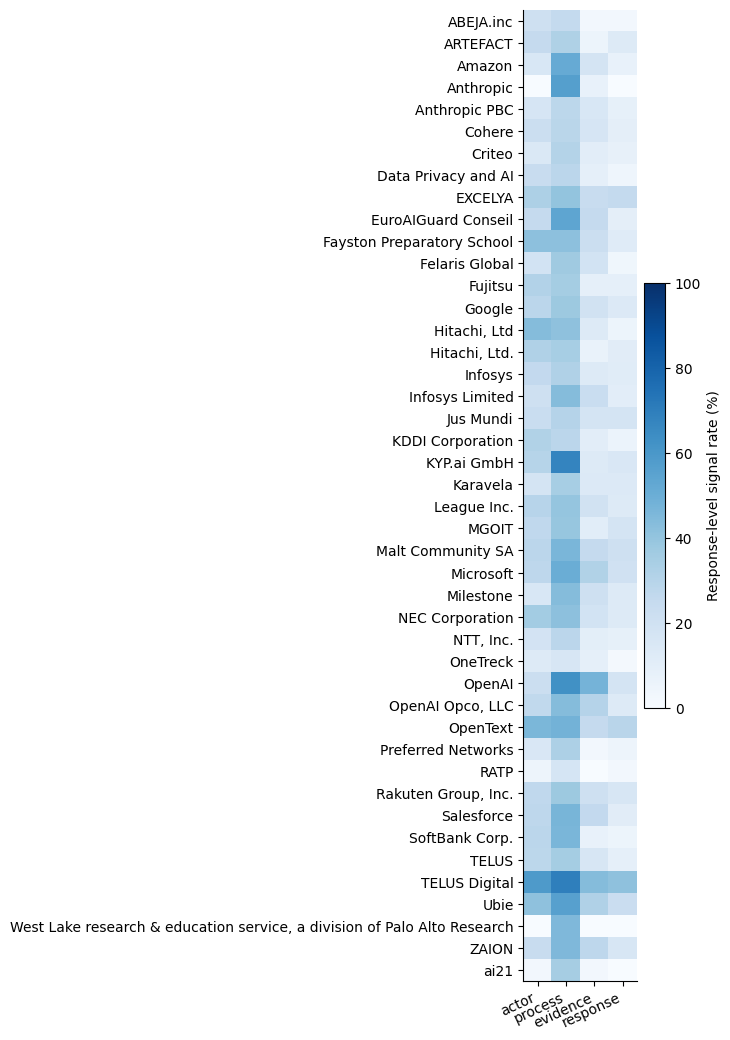

**RQ1_F2 — Proximity sensitivity; orange bars show medians across latest reports**

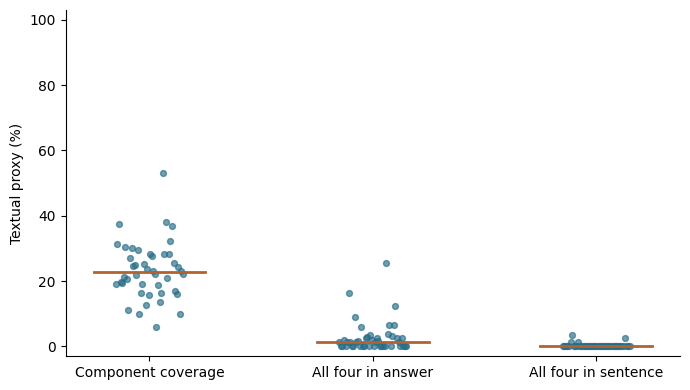

**RQ1_T1 — Component signal prevalence; report-weighted rates and answer-level counts**

,component,n_organisation_labels,mean_report_rate_percent,median_report_rate_percent,answers_with_signal,substantive_answers
0,actor,44,24.652987,25.543478,626,2454
1,process,44,40.062781,39.495798,970,2454
2,evidence,44,16.758934,16.307413,426,2454
3,response,44,11.630947,11.035008,295,2454


**RQ1_T2 — Traceable candidate examples for manual checking; dictionary matches are not final codes**

,Organization,report_id,row_id,source_rows,question,answer,actor_terms,process_terms,evidence_terms,response_terms,candidate_sentence
2505,Infosys Limited,dccf0fddf36ade046248,8a9f4988e7f05785dae1,2631,How does your organization implement AI-specif...,i. Infosys assesses cybersecurity risks throug...,management,assessing; assessments; audits; monitoring; re...,risk register,remediation,Infosys follows a structured vulnerability man...
1669,EXCELYA,23af318b950aed88eea6,a40148b06afed191a3ab,1755,"Following deployment, how do you use incident ...",a { text-decoration: none; color: #464feb; } t...,management,assessment; monitoring; review; reviews; testing,documentation; incident reports; records,corrective actions; incident management; remed...,The organization records identified issues and...
871,Malt Community SA,2ed75b5b0cfb3f43b063,af528c8736d5abb4c473,913,Please describe how AI risk management is inte...,The governance structure distinguishes between...,board; committee; oversight,approve; approved; assessments; evaluation; mo...,documentation,remediation; rollback,"It reviews the relevant risk classification, i..."
1667,EXCELYA,23af318b950aed88eea6,9c111b8dc0b0db143f07,1753,How does your organization monitor the interac...,Our organization deploys AI agents exclusively...,management,approved; assess; assessment; monitoring; revi...,documented; records,incident management,Review of incident management records.
2017,"Hitachi, Ltd.",177d4475c43452c2659c,72a0652b2bd0bcaa33bb,2119,Please provide a consolidated description of y...,In alignment with the Guiding Principles for t...,management,assessment; monitoring; review,assurance,address risks,In alignment with the Guiding Principles for t...
19,Microsoft,cce717d4e1af3646e9d4,f8c772df852bbbb5a05f,21,Please describe examples of how your organizat...,"Microsoft collaborates with industry peers, ac...",committee; management,assess; assessment; assessments; audit; evalua...,assurance; certification,incident response,
42,Microsoft,cce717d4e1af3646e9d4,8b387ed3bd52be8cc6bd,44,Please describe the main security measures you...,Microsoft’s approach to AI cybersecurity build...,management,approval; approved; assessments; audit; evalua...,assurance,escalated; escalation; incident response,
28,Microsoft,cce717d4e1af3646e9d4,a9ea3e0f294fcdd570e4,30,Please provide a consolidated description of y...,Microsoft applies a comprehensive and layered ...,board; executive; management; oversight,assess; assessment; assessments; evaluation; e...,documentation,escalation; incident response,
836,Malt Community SA,2ed75b5b0cfb3f43b063,0acf0375f7956d692450,878,Please provide a consolidated description of y...,Malt distinguishes between recommendation syst...,committee; oversight,approved; evaluates; evaluation; evaluations; ...,documented,rollback,
3265,Milestone,9085221ef6faef5d5ac8,68616f177cc64e77474b,3505,How does your organization implement AI-specif...,Milestone assess cybersecurity risks through a...,executive; management,approved; assess; assessing; monitoring; proce...,documentation; records,address risks; address vulnerabilities,


C:\Users\bhavi\AppData\Local\Temp\ipykernel_12580\1522801069.py:37: UserWarning: Glyph 26666 (\N{CJK UNIFIED IDEOGRAPH-682A}) missing from font(s) DejaVu Sans.
  pdf.savefig(fig,bbox_inches='tight');plt.close(fig)
C:\Users\bhavi\AppData\Local\Temp\ipykernel_12580\1522801069.py:37: UserWarning: Glyph 24335 (\N{CJK UNIFIED IDEOGRAPH-5F0F}) missing from font(s) DejaVu Sans.
  pdf.savefig(fig,bbox_inches='tight');plt.close(fig)
C:\Users\bhavi\AppData\Local\Temp\ipykernel_12580\1522801069.py:37: UserWarning: Glyph 20250 (\N{CJK UNIFIED IDEOGRAPH-4F1A}) missing from font(s) DejaVu Sans.
  pdf.savefig(fig,bbox_inches='tight');plt.close(fig)
C:\Users\bhavi\AppData\Local\Temp\ipykernel_12580\1522801069.py:37: UserWarning: Glyph 31038 (\N{CJK UNIFIED IDEOGRAPH-793E}) missing from font(s) DejaVu Sans.
  pdf.savefig(fig,bbox_inches='tight');plt.close(fig)


In [25]:
# RQ1 | Export component coverage, proximity sensitivity, prevalence and the response audit trail.
heat(latest.set_index('Organization')[COMPONENTS].sort_index(),'RQ1_F1','Latest-report component signal rates; equal answer weighting within report')
contrast=latest[['Organization','component_coverage','all_four_answer','all_four_sentence']].copy()
fig,ax=plt.subplots(figsize=(7,4))
labels=['Component coverage','All four in answer','All four in sentence']
for i,col in enumerate(contrast.columns[1:]):
    y=contrast[col].values;ax.scatter(i+np.linspace(-.15,.15,len(y)),y,s=18,alpha=.65,color='#276c86')
    ax.plot([i-.25,i+.25],[np.median(y)]*2,color='#b3612f',lw=2)
ax.set_xticks(range(3),labels);ax.set(ylabel='Textual proxy (%)',ylim=(-3,103))
figout(fig,contrast,'RQ1_F2','Proximity sensitivity; orange bars show medians across latest reports')
prevalence=pd.DataFrame([{'component':c,'n_organisation_labels':len(latest),'mean_report_rate_percent':latest[c].mean(),
    'median_report_rate_percent':latest[c].median(),'answers_with_signal':int(scores_for_primary[c].sum()),
    'substantive_answers':len(scores_for_primary)} for c in COMPONENTS])
tabout(prevalence,'RQ1_T1','Component signal prevalence; report-weighted rates and answer-level counts')
audit=scores_for_primary.sort_values(['all_four_sentence','all_four_answer','word_count'],ascending=False).head(12)
tabout(audit[['Organization','report_id','row_id','source_rows','question','answer',*[c+'_terms' for c in COMPONENTS],'candidate_sentence']],
    'RQ1_T2','Traceable candidate examples for manual checking; dictionary matches are not final codes')

## RQ2 Results
M7. Stages are mapped from question context; broad lifecycle questions can map to more than one stage. Unmapped titles remain cross-cutting/unresolved. A question mapping is an analytical choice that must be checked; it is not a stage label supplied by the OECD.

**RQ2_F1 — Lifecycle signal rates; equal latest-report weighting among substantive mapped answers**

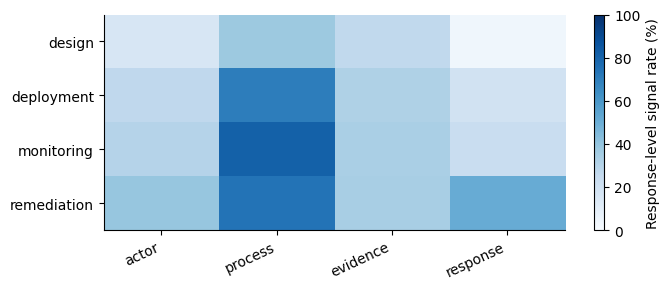

**RQ2_F2 — Availability versus candidate rate; denominators are mapped questions and substantive answers respectively**

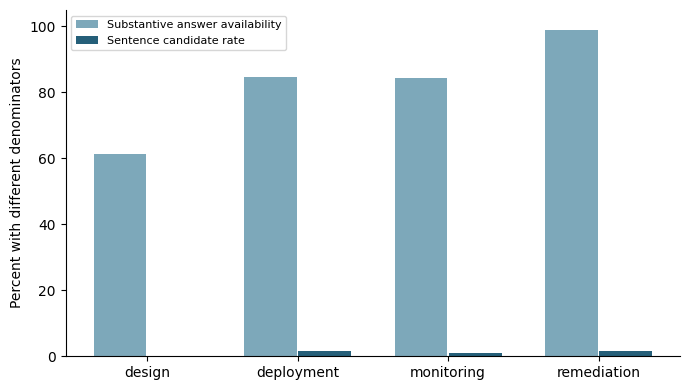

**RQ2_T1 — Missing dictionary signals by stage; multi-stage answers recur across stages**

,stages,missing_signals,n_answer_stage_pairs,stage_denominator,percent
3,deployment,"actor, process, evidence, response",62,206,30.097087
2,deployment,"actor, evidence, response",49,206,23.786408
5,deployment,"actor, response",31,206,15.048544
6,deployment,all four detected,15,206,7.281553
7,deployment,evidence,13,206,6.310680
8,deployment,"evidence, response",12,206,5.825243
12,deployment,response,9,206,4.368932
0,deployment,actor,4,206,1.941748
1,deployment,"actor, evidence",4,206,1.941748
4,deployment,"actor, process, response",3,206,1.456311


**RQ2_T2 — Complete question-title mapping audit for human review; titles are never scored as answers**

,question,n_reports,n_substantive,mapped_stages
0,"Across the AI system lifecycle, what steps doe...",31,0,cross-cutting or unresolved
1,Any further comments and for implementation do...,25,9,cross-cutting or unresolved
2,Any further comments and implementation docume...,31,10,cross-cutting or unresolved
3,Are any national AI safety / security institut...,9,7,cross-cutting or unresolved
4,Are quantitative and/or qualitative risk evalu...,25,25,cross-cutting or unresolved
...,...,...,...,...
120,What research or investment is your organizati...,25,25,cross-cutting or unresolved
121,What research or investment is your organizati...,25,24,cross-cutting or unresolved
122,What security measures are used in testing AI ...,31,28,cross-cutting or unresolved
123,What steps does your organization take to addr...,25,25,remediation


In [26]:
# RQ2 | Export stage profiles, availability, missing signals and the question mapping audit.
stage_mean=by_stage_primary.groupby('stages')[COMPONENTS].mean().reindex(STAGES)
heat(stage_mean,'RQ2_F1','Lifecycle signal rates; equal latest-report weighting among substantive mapped answers')
av=expanded.loc[expanded.report_id.isin(latest_ids)].groupby('stages').agg(mapped_questions=('row_id','size'),substantive=('eligible','sum')).reindex(STAGES)
av['substantive_percent']=100*av.substantive/av.mapped_questions
av=av.join(by_stage_primary.groupby('stages').agg(candidate_rate=('all_four_sentence','mean'),n_reports=('report_id','nunique')))
fig,ax=plt.subplots(figsize=(7,4));pos=np.arange(4)
ax.bar(pos-.18,av.substantive_percent,.35,label='Substantive answer availability',color='#7da8ba')
ax.bar(pos+.18,av.candidate_rate,.35,label='Sentence candidate rate',color='#255f79')
ax.set_xticks(pos,STAGES);ax.set(ylabel='Percent with different denominators',ylim=(0,105));ax.legend(fontsize=8)
figout(fig,av.rename_axis('stage').reset_index(),'RQ2_F2','Availability versus candidate rate; denominators are mapped questions and substantive answers respectively')
pat=stage_valid.loc[stage_valid.report_id.isin(latest_ids)].copy()
pat['missing_signals']=pat.apply(lambda r:', '.join(c for c in COMPONENTS if not r[c]) or 'all four detected',axis=1)
patterns=pat.groupby(['stages','missing_signals']).size().rename('n_answer_stage_pairs').reset_index()
patterns['stage_denominator']=patterns.groupby('stages').n_answer_stage_pairs.transform('sum')
patterns['percent']=100*patterns.n_answer_stage_pairs/patterns.stage_denominator
tabout(patterns.sort_values(['stages','n_answer_stage_pairs'],ascending=[True,False]),'RQ2_T1','Missing dictionary signals by stage; multi-stage answers recur across stages')
qm=d.groupby('question').agg(n_reports=('report_id','nunique'),n_substantive=('eligible','sum')).reset_index()
qm['mapped_stages']=qm.question.map(lambda q:'|'.join(map_stages(q)) or 'cross-cutting or unresolved')
tabout(qm,'RQ2_T2','Complete question-title mapping audit for human review; titles are never scored as answers')

## RQ3 Results
M8. This dataset supports countries and reporting periods. It does not support sector or document-type comparisons. Period plots use all reports; country plots use latest reports. No country-level hypothesis tests are claimed with this small voluntary sample. Repeated organisation names may conceal aliases, so paired results cover exact labels only.

**RQ3_F1 — Country comparison in latest reports; observations are organisation labels**

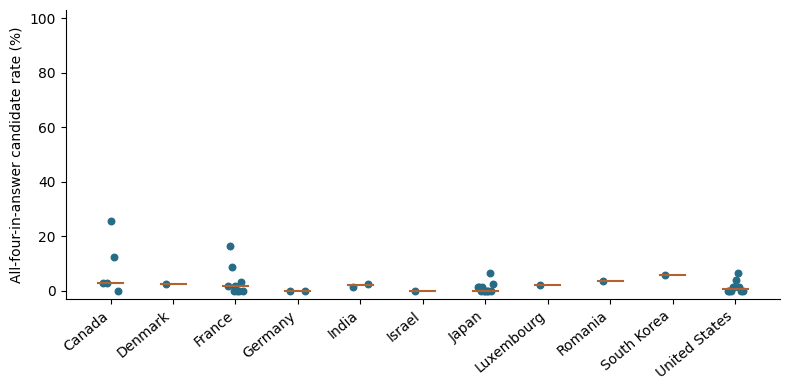

**RQ3_F2 — All-report period comparison; repeated organisations and template changes prevent causal interpretation**

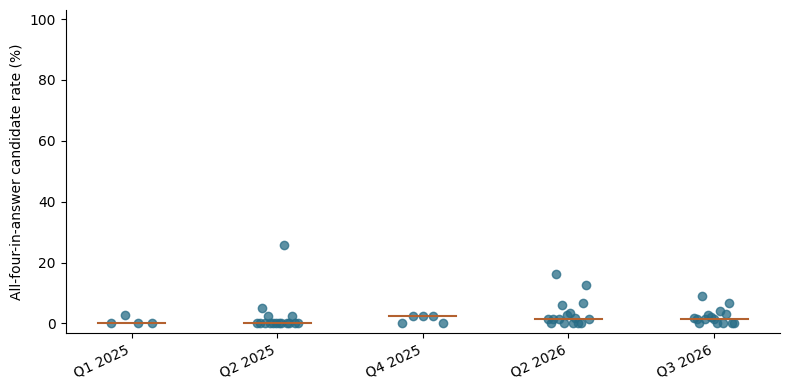

**RQ3_T1 — Country-by-period sample composition; no representation of all companies is implied**

,Country,Reporting Period,n_reports,n_organisation_labels
0,Canada,Q2 2025,2,2
1,Canada,Q2 2026,2,2
2,Canada,Q3 2026,2,2
3,Denmark,Q4 2025,1,1
4,France,Q2 2026,5,5
5,France,Q3 2026,4,4
6,Germany,Q2 2025,2,2
7,Germany,Q3 2026,1,1
8,India,Q3 2026,1,1
9,India,Q4 2025,1,1


**RQ3_T2 — Matched exact-label earliest/latest reports on identical substantive questions; changed wording is excluded**

,Organization,earliest_report,latest_report,earliest_period,latest_period,n_common_answered_questions,earliest_candidate_rate,latest_candidate_rate,change_percentage_points,same_questionnaire_fingerprint
0,Data Privacy and AI,cedebfe1ffc8e6a9a869,aabd1eb320ff67a29b37,Q2 2025,Q3 2026,2,0.0,0.0,0.0,False
1,Fayston Preparatory School,8e138cb8b0795735f640,6c9a65482a4310885386,Q2 2025,Q2 2026,3,0.0,0.0,0.0,False
2,Fujitsu,7f446b8220c259d0f37f,c886f3347c50bc613c49,Q2 2025,Q3 2026,3,0.0,0.0,0.0,False
3,Google,15a2e6327ee55a2690f3,3c553914d72f1957b42c,Q2 2025,Q2 2026,3,0.0,0.0,0.0,False
4,KDDI Corporation,e33d71630a5e7a62ff6e,00b26cd7065ffe3d94b5,Q2 2025,Q2 2026,2,0.0,0.0,0.0,False
5,MGOIT,2bb575f8099631b41c8a,7ffe366e69e123598e6d,Q1 2025,Q2 2026,3,0.0,0.0,0.0,False
6,Microsoft,69f622c1b183d9ce0dd1,cce717d4e1af3646e9d4,Q2 2025,Q3 2026,3,0.0,0.0,0.0,False
7,NEC Corporation,e8b22bc9d505daea2c8f,2bee0098623f0eb6ca8b,Q2 2025,Q3 2026,3,0.0,0.0,0.0,False
8,"NTT, Inc.",ef1ba573f157b1c959ae,705f29548743aa32bd5c,Q1 2025,Q2 2026,3,0.0,0.0,0.0,False
9,"Rakuten Group, Inc.",e4ce3f8f64c77d0be2a1,4d4a498b4acce41fbff2,Q2 2025,Q3 2026,1,0.0,0.0,0.0,False


In [27]:
# RQ3 | Export country/period profiles, sample composition and common-question paired sensitivity.
countries=sorted(latest.Country.unique());fig,ax=plt.subplots(figsize=(max(8,.7*len(countries)),4))
for i,country in enumerate(countries):
    vals=latest.loc[latest.Country.eq(country),'all_four_answer'].values
    ax.scatter(i+np.linspace(-.12,.12,len(vals)),vals,s=22,color='#276c86')
    ax.plot([i-.2,i+.2],[np.median(vals)]*2,color='#b3612f')
ax.set_xticks(range(len(countries)),countries,rotation=40,ha='right');ax.set(ylabel='All-four-in-answer candidate rate (%)',ylim=(-3,103))
figout(fig,latest[['Organization','Country','all_four_answer','n_answers']],'RQ3_F1','Country comparison in latest reports; observations are organisation labels')
periods=scores[['Reporting Period','period_sort']].drop_duplicates().sort_values('period_sort')['Reporting Period'].tolist()
fig,ax=plt.subplots(figsize=(8,4))
for i,period in enumerate(periods):
    y=scores.loc[scores['Reporting Period'].eq(period),'all_four_answer'].values
    ax.scatter(i+np.linspace(-.14,.14,len(y)),y,color='#276c86',alpha=.75)
    ax.plot([i-.23,i+.23],[np.median(y)]*2,color='#b3612f')
ax.set_xticks(range(len(periods)),periods,rotation=25,ha='right');ax.set(ylabel='All-four-in-answer candidate rate (%)',ylim=(-3,103))
figout(fig,scores[['Organization','report_id','Reporting Period','all_four_answer','n_answers']],'RQ3_F2','All-report period comparison; repeated organisations and template changes prevent causal interpretation')
composition=reports.groupby(['Country','Reporting Period']).agg(n_reports=('report_id','nunique'),n_organisation_labels=('Organization','nunique')).reset_index()
tabout(composition,'RQ3_T1','Country-by-period sample composition; no representation of all companies is implied')
paired=[]
for org,g in reports.groupby('Organization'):
    g=g.sort_values(['date','period_sort','report_id'])
    if len(g)<2:continue
    first,last=g.iloc[0],g.iloc[-1]
    aa=valid.loc[valid.report_id.eq(first.report_id)].set_index('question')
    bb=valid.loc[valid.report_id.eq(last.report_id)].set_index('question')
    common=aa.index.intersection(bb.index)
    rate_a=100*aa.loc[common,'all_four_answer'].mean() if len(common) else np.nan
    rate_b=100*bb.loc[common,'all_four_answer'].mean() if len(common) else np.nan
    paired.append({'Organization':org,'earliest_report':first.report_id,'latest_report':last.report_id,
        'earliest_period':first['Reporting Period'],'latest_period':last['Reporting Period'],
        'n_common_answered_questions':len(common),'earliest_candidate_rate':rate_a,
        'latest_candidate_rate':rate_b,'change_percentage_points':rate_b-rate_a,
        'same_questionnaire_fingerprint':first.template_fingerprint==last.template_fingerprint})
paired_frame=pd.DataFrame(paired,columns=['Organization','earliest_report','latest_report','earliest_period','latest_period',
    'n_common_answered_questions','earliest_candidate_rate','latest_candidate_rate','change_percentage_points','same_questionnaire_fingerprint'])
tabout(paired_frame,'RQ3_T2','Matched exact-label earliest/latest reports on identical substantive questions; changed wording is excluded')

## RQ4 Results
M9. Principle coverage is the fraction of five principle vocabularies mentioned at least once. Candidate chain rate is the fraction of substantive answers with all four accountability component signals. These have different denominators and meanings; score differences are descriptive, not proof of ethics washing.

**RQ4_F1 — Association between principle mentions and answer-level accountability co-occurrence candidates**

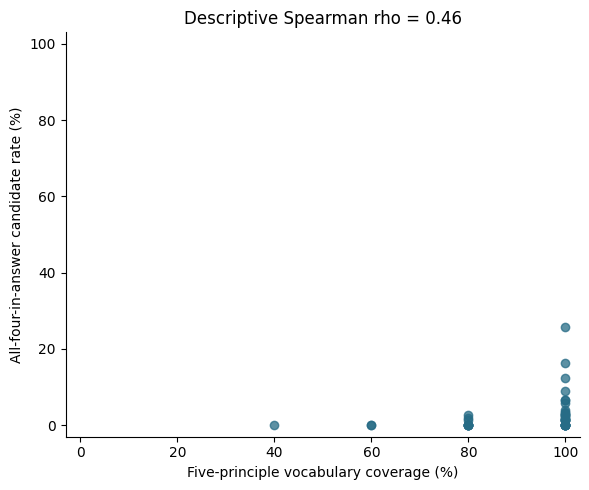

**RQ4_F2 — Paired score differences; constructs and denominators differ**

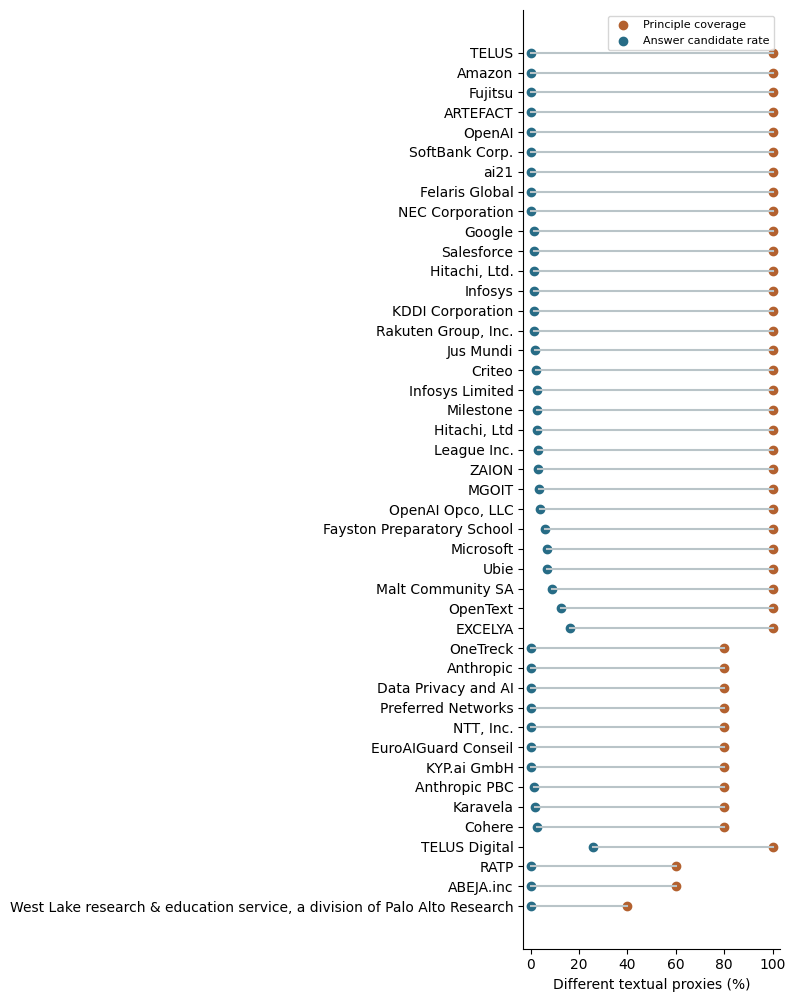

**RQ4_T1 — Descriptive high/low discordance at prespecified thresholds; no validated governance standard**

,threshold_percent,principles,candidate_rate,n_organisation_labels,denominator,percent
0,25,low,low,0,44,0.000000
1,25,low,high,0,44,0.000000
2,25,high,low,43,44,97.727273
3,25,high,high,1,44,2.272727
4,50,low,low,1,44,2.272727
5,50,low,high,0,44,0.000000
6,50,high,low,43,44,97.727273
7,50,high,high,0,44,0.000000
8,75,low,low,3,44,6.818182
9,75,low,high,0,44,0.000000


**RQ4_T2 — Largest absolute-score-discordance cases with source responses; requires qualitative interpretation**

,Organization,report_id,principle_coverage,candidate_rate,illustrative_row_id,source_rows,question,answer,candidate_sentence
0,ARTEFACT,a766683e0636e2bccc7b,100.0,0.0,b595e5318b0658c08410,2084,"If yes, please describe key research or invest...",We have conducted a research project in partne...,
1,Amazon,e9245f40159941978749,100.0,0.0,69eaf7071d63565a2331,2747,What research or investment is your organizati...,Amazon pursues research and investment initiat...,
2,Felaris Global,10649100904a64788def,100.0,0.0,9211752538bb8211602e,1305,Please provide a consolidated description of y...,"Felaris runs a governance-by-design approach, ...",
3,Fujitsu,c886f3347c50bc613c49,100.0,0.0,cb83bb9d0618649c98d8,1195,"If yes, please describe key research or invest...","Fujitsu is advancing research, development, im...",
4,NEC Corporation,2bee0098623f0eb6ca8b,100.0,0.0,26cb1b2be7e375e59e57,971,Describe key privacy measures and data-protect...,We have established and published the “NEC Pri...,
5,OpenAI,07f340a3d8c8829f1d02,100.0,0.0,edf2d4099db7d00e287b,3074,Does your organization collaborate with civil ...,OpenAI’s UN General Assembly (UNGA) activation...,


In [28]:
# RQ4 | Export principle/proxy comparisons, threshold sensitivity and traceable discordance cases.
r=rho(latest.principle_coverage,latest.all_four_answer)
fig,ax=plt.subplots(figsize=(6,5));ax.scatter(latest.principle_coverage,latest.all_four_answer,color='#276c86',alpha=.75)
ax.set(xlabel='Five-principle vocabulary coverage (%)',ylabel='All-four-in-answer candidate rate (%)',xlim=(-3,103),ylim=(-3,103))
ax.set_title('Descriptive Spearman rho = '+(f'{r:.2f}' if pd.notna(r) else 'undefined'))
figout(fig,latest[['Organization','report_id','principle_coverage','all_four_answer']],'RQ4_F1','Association between principle mentions and answer-level accountability co-occurrence candidates')
order=latest.assign(gap=lambda z:z.principle_coverage-z.all_four_answer).sort_values('gap')
fig,ax=plt.subplots(figsize=(8,max(4,.23*len(order))))
for i,(_,row) in enumerate(order.iterrows()):ax.plot([row.principle_coverage,row.all_four_answer],[i,i],color='#b9c4c8')
ax.scatter(order.principle_coverage,range(len(order)),label='Principle coverage',color='#b3612f')
ax.scatter(order.all_four_answer,range(len(order)),label='Answer candidate rate',color='#276c86')
ax.set_yticks(range(len(order)),order.Organization.map(lambda s:s.encode('ascii','ignore').decode()));ax.set(xlabel='Different textual proxies (%)',xlim=(-3,103));ax.legend(fontsize=8)
figout(fig,order[['Organization','report_id','principle_coverage','all_four_answer','gap']],'RQ4_F2','Paired score differences; constructs and denominators differ')
rows=[]
for threshold in [25,50,75]:
    a=latest.principle_coverage.ge(threshold);b=latest.all_four_answer.ge(threshold)
    for ap,bp in itertools.product([False,True],repeat=2):
        count=int(((a==ap)&(b==bp)).sum())
        rows.append({'threshold_percent':threshold,'principles':'high' if ap else 'low','candidate_rate':'high' if bp else 'low',
            'n_organisation_labels':count,'denominator':len(latest),'percent':100*count/len(latest)})
tabout(pd.DataFrame(rows),'RQ4_T1','Descriptive high/low discordance at prespecified thresholds; no validated governance standard')
cases=[]
for _,row in order.assign(abs_gap=order.gap.abs()).sort_values(['abs_gap','Organization'],ascending=[False,True]).head(6).iterrows():
    resp=valid.loc[valid.report_id.eq(row.report_id)].sort_values(['all_four_answer','word_count'],ascending=False).iloc[0]
    cases.append({'Organization':row.Organization,'report_id':row.report_id,'principle_coverage':row.principle_coverage,
        'candidate_rate':row.all_four_answer,'illustrative_row_id':resp.row_id,'source_rows':resp.source_rows,
        'question':resp.question,'answer':resp.answer,'candidate_sentence':resp.candidate_sentence})
tabout(pd.DataFrame(cases),'RQ4_T2','Largest absolute-score-discordance cases with source responses; requires qualitative interpretation')

In [29]:
# M10 | Create organisation-disjoint pilot and held-out review samples and blinded coder sheets.
organisations=sorted(valid.Organization.unique())
rng=np.random.default_rng(42);rng.shuffle(organisations)
pilot_orgs=set(organisations[:max(1,len(organisations)//4)])
pool=valid.copy()
pool['review_phase']=np.where(pool.Organization.isin(pilot_orgs),'pilot','held_out')
review=[]
for (phase,flag),g in pool.groupby(['review_phase','all_four_answer']):
    size=min(75,len(g));take=g.sample(n=size,random_state=42).copy()
    take['sampling_stratum']=phase+('_candidate_positive' if flag else '_candidate_negative')
    take['stratum_population']=len(g);take['stratum_sample']=size;take['sample_weight']=len(g)/size
    review.append(take)
review=pd.concat(review,ignore_index=True)
cols=['row_id','report_id','Organization','Country','review_phase','question','answer','source_rows','all_four_answer',
    'candidate_sentence','sampling_stratum','stratum_population','stratum_sample','sample_weight']
review=review[cols].copy()
review['input_sha256']=raw_profile['sha256']
for col in COMPONENTS+['actor_process_link','process_evidence_link','evidence_response_link','confirmed_complete','reviewer','supporting_quote','review_note']:
    review[col]=''
review.to_csv(OUT/'human_validation_TEMPLATE.csv',index=False)
blind=review.drop(columns=['all_four_answer','candidate_sentence','sampling_stratum','sample_weight','stratum_population','stratum_sample'])
blind.to_csv(OUT/'coder_A_TEMPLATE.csv',index=False);blind.to_csv(OUT/'coder_B_TEMPLATE.csv',index=False)
review[['row_id','Organization','review_phase','sampling_stratum','stratum_population','stratum_sample','sample_weight','input_sha256']].to_csv(OUT/'validation_sampling_design.csv',index=False)
print('Pilot organisations:',len(pilot_orgs),'| Held-out organisations:',len(organisations)-len(pilot_orgs))
print('Review sample rows:',len(review),'; freeze rules after pilot and evaluate only held-out labels.')


Pilot organisations: 11 | Held-out organisations: 33
Review sample rows: 224 ; freeze rules after pilot and evaluate only held-out labels.


In [30]:
# M10 | Optional reviewed-label diagnostics; missing human inputs do not block exploratory figures.
# Set paths after real independent review. Never manufacture labels to make this cell run.
GOLD_FILE=os.environ.get('OECD_GOLD_FILE') or None
CODER_A_FILE=os.environ.get('OECD_CODER_A_FILE') or None
CODER_B_FILE=os.environ.get('OECD_CODER_B_FILE') or None
if GOLD_FILE is not None:
    from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
    gold=pd.read_csv(GOLD_FILE)
    assert gold.row_id.is_unique and len(gold)>0
    assert gold.input_sha256.eq(raw_profile['sha256']).all(), 'Labels belong to a different CSV'
    assert gold.confirmed_complete.isin([0,1]).all()
    for col in COMPONENTS:
        assert gold[col].isin([0,1,2]).all(), 'Complete specificity codes 0/1/2 are required'
    links=['actor_process_link','process_evidence_link','evidence_response_link']
    assert gold[links].isin([0,1]).all().all()
    complete=gold[COMPONENTS].eq(2).all(axis=1)&gold[links].eq(1).all(axis=1)
    assert gold.confirmed_complete.astype(bool).eq(complete).all(), 'Confirmed chain must match specificity and explicit links'
    source=valid.set_index('row_id')
    for row in gold.loc[gold.confirmed_complete.eq(1)].itertuples():
        assert row.row_id in source.index and isinstance(row.supporting_quote,str) and row.supporting_quote in source.loc[row.row_id,'answer'], 'Complete chains require source quotations'
    design=review[['row_id','review_phase','sample_weight']]
    gold=gold.drop(columns=['review_phase','sample_weight'],errors='ignore').merge(design,on='row_id',validate='one_to_one')
    gold=gold.loc[gold.review_phase.eq('held_out')].copy()
    assert len(gold)>0, 'No completed held-out labels'
    joined=valid[['row_id','all_four_answer']].merge(gold[['row_id','confirmed_complete','sample_weight']],on='row_id',validate='one_to_one')
    assert len(joined)==len(gold)>0, 'Every reviewed row must match current input'
    assert pd.to_numeric(joined.sample_weight,errors='raise').gt(0).all()
    pr,rc,f1,_=precision_recall_fscore_support(joined.confirmed_complete,joined.all_four_answer,average='binary',sample_weight=joined.sample_weight,zero_division=0)
    validation=pd.DataFrame([{'weighted_precision':pr,'weighted_recall':rc,'weighted_f1':f1,'n_reviewed':len(joined)}])
    validation.to_csv(OUT/'human_validation_metrics.csv',index=False);display(validation)
    pd.DataFrame(confusion_matrix(joined.confirmed_complete,joined.all_four_answer,labels=[0,1],sample_weight=joined.sample_weight),index=['true_0','true_1'],columns=['pred_0','pred_1']).to_csv(OUT/'weighted_confusion_matrix.csv')
else:print('Human-confirmed validity not measured: no gold labels supplied. All sixteen outputs remain exploratory.')
if CODER_A_FILE is not None and CODER_B_FILE is not None:
    from sklearn.metrics import cohen_kappa_score
    aa=pd.read_csv(CODER_A_FILE);bb=pd.read_csv(CODER_B_FILE)
    assert aa.row_id.is_unique and bb.row_id.is_unique and set(aa.row_id)==set(bb.row_id)
    assert aa.input_sha256.eq(raw_profile['sha256']).all() and bb.input_sha256.eq(raw_profile['sha256']).all()
    assert set(aa.row_id).issubset(set(review.row_id)), 'Unknown sampled row IDs'
    held_out=set(review.loc[review.review_phase.eq('held_out'),'row_id'])
    aa=aa.loc[aa.row_id.isin(held_out)];bb=bb.loc[bb.row_id.isin(held_out)]
    cc=aa.merge(bb,on='row_id',suffixes=('_A','_B'),validate='one_to_one');agreements=[]
    for col in COMPONENTS+['actor_process_link','process_evidence_link','evidence_response_link']:
        a,b=cc[col+'_A'],cc[col+'_B'];allowed=[0,1,2] if col in COMPONENTS else [0,1]
        assert len(a)>0 and a.isin(allowed).all() and b.isin(allowed).all()
        k=np.nan if len(set(a)|set(b))<2 else cohen_kappa_score(a,b,labels=allowed,weights='quadratic' if col in COMPONENTS else None)
        agreements.append({'dimension':col,'n':len(a),'raw_agreement':float(a.eq(b).mean()),'kappa':k})
    agreements=pd.DataFrame(agreements);agreements.to_csv(OUT/'intercoder_agreement.csv',index=False);display(agreements)
if GOLD_FILE is not None:
    confirmed=gold[['row_id','confirmed_complete',*COMPONENTS,*links,'supporting_quote']].copy()
    confirmed.to_csv(OUT/'confirmed_reviewed_chains.csv',index=False)
    print('Confirmed label summaries refer only to reviewed held-out answers, not all reports.')


Human-confirmed validity not measured: no gold labels supplied. All sixteen outputs remain exploratory.


In [31]:
# M12 | Verify sixteen result IDs, save reproducibility metadata and ZIP the current run.
expected={f'RQ{q}_{kind}{i}' for q in range(1,5) for kind in ['F','T'] for i in [1,2]}
assert len(ARTIFACTS)==16 and {r['id'] for r in ARTIFACTS}==expected
for ident in expected:
    assert (OUT/(ident+'.pdf')).stat().st_size>100 and (OUT/(ident+'.csv')).stat().st_size>10
versions={}
for pkg in ['pandas','numpy','matplotlib','scipy','scikit-learn']:
    try:versions[pkg]=importlib.metadata.version(pkg)
    except importlib.metadata.PackageNotFoundError:versions[pkg]='not installed'
manifest={'run_id':RUN_ID,'input':str(INPUT_FILE),'input_sha256':raw_profile['sha256'],
    'cutoff':str(CUTOFF.date()),'versions':versions,'python':platform.python_version(),
    'n_latest_reports':len(latest),'n_all_reports':len(scores),'outputs':ARTIFACTS,
    'status':'actual CSV-based exploratory text analysis; accountability links require human confirmation',
    'organisation_identity':'exact supplied labels; no automatic corporate alias merging',
    'rq3_change':'country and period comparisons replace unavailable sector/document-type fields'}
(OUT/'run_manifest.json').write_text(json.dumps(manifest,indent=2))
(OUT/'figure_table_captions.md').write_text('\n\n'.join(r['id']+' — '+r['caption'] for r in ARTIFACTS))
checksums={p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in OUT.iterdir() if p.is_file()}
(OUT/'checksums.json').write_text(json.dumps(checksums,indent=2))
RESULT_ZIP=shutil.make_archive(str(ROOT/('OECD_CSV_Actual_Results_'+RUN_ID)),'zip',OUT)
print('Created',len(ARTIFACTS),'RQ-linked outputs:',RESULT_ZIP)
display(FileLink(RESULT_ZIP))
# Provide a stable pointer without changing the immutable timestamped run.
(ROOT/'latest_run.json').write_text(json.dumps({'directory':str(OUT),'zip':RESULT_ZIP,'input_sha256':raw_profile['sha256']},indent=2))


Created 16 RQ-linked outputs: c:\Users\bhavi\Downloads\Team LogicFlow\outputs\OECD_CSV_Actual_Results_20261109T115856383383Z.zip


c:\Users\bhavi\Downloads\Team LogicFlow\outputs\OECD_CSV_Actual_Results_20261109T115856383383Z.zip

317

## Interpretation and publication next steps
When executed, the measurement routines calculate their outputs from the supplied CSV. The executed copy contains real exploratory measurements. Empty human-review templates are inputs for later work, not results. Dictionary recall and precision remain unknown until reviewed labels are supplied. A same-sentence co-occurrence is not a verified actor–process–evidence–response chain. Confirm exact relationships, identify artefacts, inspect public links and separate current controls from intentions before drawing accountability conclusions.

The CSV may contain non-corporate organisations. The automated census therefore describes **organisation-labelled reports**. The final corporate analysis requires a documented corporate-eligibility screen and alias review. Country and period comparisons are descriptive. Questionnaire differences and repeated organisation labels constrain comparability.

Target journal: The Journal of Strategic Information Systems. Reference: Papagiannidis, Mikalef and Conboy (2025), doi:10.1016/j.jsis.2024.101885. No separate sample-paper PDF was supplied; the journal record/abstract, not a full-text replication protocol, informed this design.